# L-WMC 接入 ZEUS：最小实验

先在 CPU 上运行 ID 61 和 ID 14。算法和实验代码暂时都留在本 notebook，稳定后再整理成 `.py`。

L-WMC 用其他样本重建每个点，让距离较远的样本受到更大的惩罚，并鼓励重建系数总和接近 1。再把重建关系转成连接矩阵，用谱聚类分组。标签只用于指定最终组数和评分。

这里只使用线性距离权重、`lasso_lars` 求解器和固定参数，不做参数搜索。先运行两个试跑数据集，再使用完全相同的设置扩展到全部 34 个数据集。

参考：[阶段计划](../docs/plan-wmc.md)、[论文](https://proceedings.neurips.cc/paper_files/paper/2024/file/e8b782d03c623e3e587fdbcc521dd581-Paper-Conference.pdf)、本地 `vendor/WMC/NeurIPS2024-Manifold/utils/selfrepresentation.py` 的 `active_support_elastic_net`、`elastic_net_manifold_clustering` 和 `_representation_to_affinity`。

本地源码 HEAD 为 `2be324a659a66997403b667e3257e51b0d421c60`，工作区有修改；下面记录核心文件的 SHA-256。保留源码核心计算，删去未使用的求解器、指数权重、估计器类和图像加载。最终分组采用与 CPP 实验相同的 scikit-learn 谱聚类入口，因此本实验不称为论文数值复现。

In [1]:
from pathlib import Path
import hashlib
import time
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import sparse_encode
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits
from tqdm import tqdm

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

source_path = root / "vendor" / "WMC" / "NeurIPS2024-Manifold" / "utils" / "selfrepresentation.py"
source_sha256 = hashlib.sha256(source_path.read_bytes()).hexdigest()
config = {"gamma": 50, "eta": 20, "support_size": 100,
          "maxiter": 40, "n_nonzero": 50, "seed": 42, "n_init": 100}

baseline = pd.read_csv(root / "results" / "zeus_openml_baseline.csv")
baseline = baseline.loc[baseline["method"] == "scaled_zeus"].set_index("openml_id")
prediction_dir = root / "data" / "wmc_zeus"
prediction_dir.mkdir(parents=True, exist_ok=True)

print("Core source SHA-256:", source_sha256)
print(config)

Core source SHA-256: b7ea8bd7810ba17a1a29d75b2690311117372099f610634405cb2356bdaa0a8a
{'gamma': 50, 'eta': 20, 'support_size': 100, 'maxiter': 40, 'n_nonzero': 50, 'seed': 42, 'n_init': 100}


## 1. 在候选样本中求稀疏重建系数

先用 100 个候选样本求解，再检查是否需要加入其他样本；这是源码的工作集搜索。`alpha` 是求解器的惩罚强度，目标是 `0.5 * 重建误差平方 + alpha * 系数绝对值之和`。

保留源码的浮点运算顺序。在 Iris 上与原函数直接比较，最终连接矩阵的最大绝对差为 0。

In [2]:
def active_support_lasso(X, y, alpha, support_size=100, maxiter=40):
    """沿用源码工作集更新，只保留 tau=1 的 lasso_lars 路径。"""
    n_samples = len(X)
    if n_samples <= support_size:
        support = np.arange(n_samples)
    else:
        coherence = np.abs(np.dot(y, X.T))[0]
        support = np.argpartition(-coherence, support_size)[:support_size]

    previous_objective = np.inf
    for iteration in range(maxiter):
        candidates = X[support]
        coefficients = sparse_encode(
            y, candidates, algorithm="lasso_lars", alpha=alpha,
        )
        delta = (y - np.dot(coefficients, candidates)) / alpha
        objective = np.abs(coefficients[0]).sum() + alpha / 2 * np.square(delta).sum()
        if previous_objective - objective < 1e-10 * previous_objective:
            break
        previous_objective = objective

        coherence = np.abs(np.dot(delta, X.T))[0]
        coherence[support] = 0
        added = np.flatnonzero(coherence > 1 + 1e-10)
        if len(added) == 0:
            break
        if iteration == maxiter - 1:
            warnings.warn("WMC working set reached maxiter before convergence.")
            break

        active = support[np.abs(coefficients[0]) > 1e-10]
        if len(active) > 0.8 * support_size:
            support_size = min(round(max(len(active), support_size) * 1.1), n_samples)
        if len(added) + len(active) > support_size:
            count = support_size - len(active)
            order = np.argpartition(-coherence[added], count)[:count]
            added = added[order]
        support = np.concatenate([active, added])

    result = np.zeros(n_samples)
    result[support] = coefficients[0]
    return result

## 2. 从重建系数生成连接矩阵

每次排除样本自身。距离先下限截到 `1e-3`，再除以距离总和，与源码一致。追加常数列 `sqrt(eta)` 实现系数总和接近 1 的惩罚；按距离权重缩放候选样本后求解，再还原系数。

保留每行最大的 50 个非零系数，逐行归一化，取绝对值后对称化。算法函数只接收特征，不接收真实标签。

In [3]:
def wmc_affinity(X, gamma=50, eta=20, support_size=100, maxiter=40, n_nonzero=50):
    """返回 L-WMC 的稀疏连接矩阵，不做评分或参数选择。"""
    n_samples = len(X)
    rows, columns, values = [], [], []
    augmented = np.column_stack([X, np.full(n_samples, np.sqrt(eta))])

    for i in tqdm(range(n_samples), desc="L-WMC", mininterval=1.0):
        indices = np.delete(np.arange(n_samples), i)
        distances = np.linalg.norm(X[indices] - X[i], axis=1)
        weights = np.maximum(distances, 1e-3)
        weights = weights / weights.sum()

        dictionary = augmented[indices] * (1.0 / weights[:, None])
        target = augmented[i:i + 1]
        alpha = np.abs(np.dot(dictionary, target.T)).max() / gamma
        coefficients = active_support_lasso(
            dictionary, target, alpha, support_size=support_size, maxiter=maxiter,
        ) / weights

        nonzero = np.flatnonzero(coefficients)
        if len(nonzero) > n_nonzero:
            nonzero = nonzero[np.argsort(-np.abs(coefficients[nonzero]))[:n_nonzero]]
        rows.extend([i] * len(nonzero))
        columns.extend(indices[nonzero])
        values.extend(coefficients[nonzero])

    representation = sparse.csr_matrix(
        (values, (rows, columns)), shape=(n_samples, n_samples),
    )
    representation = normalize(representation, norm="l2", axis=1)
    affinity = abs(representation)
    return ((affinity + affinity.T) / 2).tocsr()

## 3. 读取一个数据集，聚类并保存预测

使用 `embeddings_scaled`，保持缓存中的样本顺序，不额外缩放或降维。只检查输入和连接矩阵能否用于本次实验；发现问题直接报错，不自动换算法或参数。

In [4]:
def run_dataset(openml_id):
    with np.load(root / "data" / "embeddings" / f"openml_{openml_id}.npz") as data:
        features = data["embeddings_scaled"].astype(np.float64)
        labels = data["labels"].copy()
        sample_indices = data["sample_indices"].copy()
    assert features.shape == (len(labels), 512) and len(sample_indices) == len(labels)
    assert np.isfinite(features).all()
    n_clusters = len(np.unique(labels))

    started = time.perf_counter()
    affinity = wmc_affinity(
        features, gamma=config["gamma"], eta=config["eta"],
        support_size=config["support_size"], maxiter=config["maxiter"],
        n_nonzero=config["n_nonzero"],
    )
    representation_seconds = time.perf_counter() - started
    assert np.isfinite(affinity.data).all() and affinity.nnz > 0
    assert np.all(affinity.diagonal() == 0) and (affinity - affinity.T).nnz == 0
    assert np.all(np.asarray(affinity.sum(axis=1)).ravel() > 0), "WMC has isolated samples"

    n_components = connected_components(affinity, directed=False, return_labels=False)

    started = time.perf_counter()
    predicted = SpectralClustering(
        n_clusters=n_clusters, affinity="precomputed", assign_labels="kmeans",
        n_init=config["n_init"], random_state=config["seed"],
    ).fit_predict(affinity)
    clustering_seconds = time.perf_counter() - started
    assert len(predicted) == len(labels) and np.isfinite(predicted).all()

    np.savez(prediction_dir / f"openml_{openml_id}.npz",
             predicted=predicted, labels=labels, sample_indices=sample_indices)
    ari = adjusted_rand_score(labels, predicted)
    row = {"openml_id": openml_id, "method": "L-WMC", "n_samples": len(labels),
           "input_dim": features.shape[1], "requested_k": n_clusters,
           "predicted_k": len(np.unique(predicted)), "n_components": n_components, "ari": ari,
           "kmeans_ari": float(baseline.loc[openml_id, "ari"]),
           "representation_seconds": representation_seconds,
           "clustering_seconds": clustering_seconds,
           "embedding_variant": "embeddings_scaled", "solver": "lasso_lars",
           "wmc_source_sha256": source_sha256, "status": "complete", **config}
    row["delta_vs_kmeans"] = ari - row["kmeans_ari"]
    print(f"ID {openml_id}: ARI {ari:.4f}, K-means {row['kmeans_ari']:.4f}, "
          f"components {n_components}, representation {representation_seconds:.1f}s, "
          f"clustering {clustering_seconds:.1f}s",
          flush=True)
    return row

## 4. CPU 小规模试跑

运行 ID 61 和 ID 14，结果写入 `results/wmc_zeus_smoke.csv`，逐样本预测保存在 `data/wmc_zeus/`。用单线程 BLAS 避免小矩阵运算反复启动多线程的开销；它不改变算法参数。

这里只报告两个试跑数据集的结果，不据此汇总 34 个数据集或判断整体优劣。

In [5]:
rows = []
with threadpool_limits(limits=1):
    for openml_id in (61, 14):
        rows.append(run_dataset(openml_id))
        smoke_results = pd.DataFrame(rows)
        smoke_results.to_csv(root / "results" / "wmc_zeus_smoke.csv", index=False)

display(smoke_results[["openml_id", "n_samples", "requested_k", "predicted_k",
                       "n_components", "ari", "kmeans_ari", "representation_seconds", "clustering_seconds"]])

ID 61: ARI 0.0087, K-means 0.8515, components 36, representation 0.3s, clustering 0.1s



E:\dev\manifold-clustering\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(



E:\dev\manifold-clustering\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


ID 14: ARI 0.0052, K-means 0.5056, components 410, representation 43.2s, clustering 1.5s


,openml_id,n_samples,requested_k,predicted_k,n_components,ari,kmeans_ari,representation_seconds,clustering_seconds
0,61,150,3,3,36,0.008722,0.851457,0.270065,0.070159
1,14,2000,10,10,410,0.005162,0.505635,43.197952,1.489337


## 5. 扩展到全部 34 个数据集

保持试跑的输入、参数和求解过程。直接使用现有 ZEUS 基线中的 34 个 ID；沿用上一步已完成的两个结果，再顺序运行剩余数据集。每完成一项就更新结果 CSV。

`n_components` 记录连接图分成多少个互不连接的部分，不要求它等于目标类别数，也不按这个数自动调参。个别数据集发生错误时只记录失败原因并继续，失败项保留在汇总表中。

In [6]:
openml_ids = sorted(baseline.index.tolist())
assert len(openml_ids) == 34

with threadpool_limits(limits=1):
    for openml_id in openml_ids:
        if openml_id not in (61, 14):
            try:
                rows.append(run_dataset(openml_id))
            except Exception as error:
                rows.append({"openml_id": openml_id, "status": "failed",
                             "error": f"{type(error).__name__}: {error}"})
                print(f"ID {openml_id}: failed: {error}", flush=True)
        results = pd.DataFrame(rows).sort_values("openml_id")
        results.to_csv(root / "results" / "wmc_zeus_openml.csv", index=False)

display(results[["openml_id", "n_samples", "requested_k", "predicted_k",
                 "n_components", "ari", "kmeans_ari", "status"]])
print("Status counts:", results["status"].value_counts().to_dict())


E:\dev\manifold-clustering\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


ID 15: ARI 0.0466, K-means 0.8128, components 108, representation 7.0s, clustering 0.3s



E:\dev\manifold-clustering\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


ID 16: ARI 0.0154, K-means 0.7403, components 291, representation 45.3s, clustering 2.9s



E:\dev\manifold-clustering\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


...


E:\dev\manifold-clustering\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(



E:\dev\manifold-clustering\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


ID 42585: ARI 0.0206, K-means 0.9505, components 80, representation 1.9s, clustering 0.2s


,openml_id,n_samples,requested_k,predicted_k,n_components,ari,kmeans_ari,status
1,14,2000,10,10,410,0.005162,0.505635,complete
2,15,699,2,2,108,0.046619,0.812814,complete
3,16,2000,10,10,291,0.015402,0.740286,complete
4,18,2000,10,10,594,0.002658,0.515612,complete
5,22,2000,10,10,368,0.007335,0.560669,complete
6,35,366,6,6,63,0.036635,0.851236,complete
7,51,294,2,2,32,-0.034358,0.436568,complete
8,53,270,2,2,42,-0.007323,0.357634,complete
9,56,435,2,2,1,0.035112,0.641866,complete
0,61,150,3,3,36,0.008722,0.851457,complete


Status counts: {'complete': 34}


## 6. 在相同数据集上比较

先比较 WMC、K-means 和 CPP 的完整结果。再与提供 K、预测完整的 LAPD 按数据集 ID 取交集，四种方法在相同数据集上重算均值。LAPD 提供 K 不保证最终输出恰好 K 个组。

保存逐数据集比较表和一张四种方法的同批均值图。缺失结果保持为空，不删掉失败记录或把不同覆盖数量的均值排在一起。

Matched K-means / CPP / WMC datasets: 34


,mean ARI
kmeans_ari,0.573642
cpp_ari,0.498960
wmc_ari,0.014943


WMC vs K-means: {'higher': 0, 'similar': 0, 'lower': 34}
Matched K-means / CPP / LAPD / WMC datasets: 27


,mean ARI
kmeans_ari,0.600688
cpp_ari,0.510208
lapd_ari,0.326491
wmc_ari,0.017957


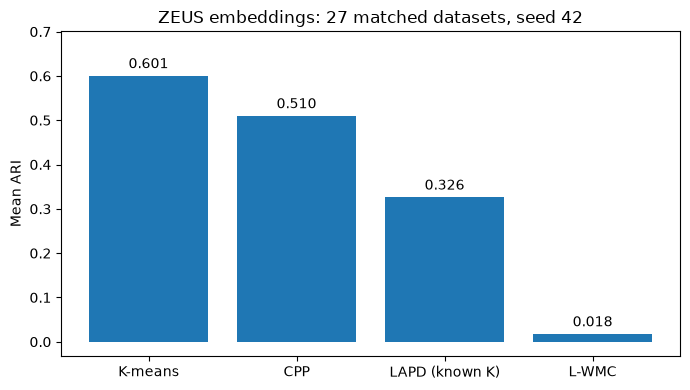

In [7]:
import matplotlib.pyplot as plt

cpp = pd.read_csv(root / "results" / "cpp_zeus_openml.csv")
cpp = cpp[["openml_id", "ari"]].rename(columns={"ari": "cpp_ari"})
lapd = pd.read_csv(root / "results" / "lapd_stage4_audit.csv")
lapd = lapd.loc[(lapd["mode"] == "known") & (lapd["status"] == "complete"),
                ["openml_id", "ari"]].rename(columns={"ari": "lapd_ari"})

comparison = results[["openml_id", "ari", "kmeans_ari", "status"]].rename(
    columns={"ari": "wmc_ari"},
).merge(cpp, on="openml_id", how="left").merge(lapd, on="openml_id", how="left")
comparison.to_csv(root / "results" / "wmc_zeus_comparison.csv", index=False)

three_columns = ["kmeans_ari", "cpp_ari", "wmc_ari"]
complete = comparison.loc[comparison["status"] == "complete"].dropna(subset=three_columns)
print("Matched K-means / CPP / WMC datasets:", len(complete))
display(complete[three_columns].mean().to_frame("mean ARI"))
delta = complete["wmc_ari"] - complete["kmeans_ari"]
print("WMC vs K-means:", {"higher": int((delta > 1e-6).sum()),
                           "similar": int((delta.abs() <= 1e-6).sum()),
                           "lower": int((delta < -1e-6).sum())})

four_columns = ["kmeans_ari", "cpp_ari", "lapd_ari", "wmc_ari"]
matched = complete.dropna(subset=four_columns)
print("Matched K-means / CPP / LAPD / WMC datasets:", len(matched))
means = matched[four_columns].mean()
display(means.to_frame("mean ARI"))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["K-means", "CPP", "LAPD (known K)", "L-WMC"], means.values)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylabel("Mean ARI")
ax.set_title(f"ZEUS embeddings: {len(matched)} matched datasets, seed 42")
ax.set_ylim(min(0, means.min() - 0.05), max(0.1, means.max() + 0.1))
fig.tight_layout()
fig.savefig(root / "results" / "wmc_zeus_matched_means.png", dpi=150)
plt.show()

## 本次完整运行记录

已在 CPU 上完成全部 34 个 OpenML 数据集的 L-WMC 实验。所有样本均有预测，实际输出组数均等于请求组数；保存的标签、样本索引和预测数量已逐数据集核对，CSV 中的 ARI 已从保存的预测重新计算核对。

[结果总结](../summary/wmc_summary.md)
